<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Ensemble Models: Bagging, Random Forests and Boosting - Solution

---

### About
One decision tree is easy to understand, but it overfits and it's unstable. **Ensembles** combine many trees to fix that:
- **Bagging** and **random forests** train many deep trees *independently* and average them: this cuts **variance**.
- **Boosting** trains small trees *in sequence*, each one fixing the last one's mistakes: this cuts **bias**.

We'll see both effects on one real problem: **is this email spam?**

### Learning Objectives
- Explain why ensembles of trees outperform a single tree (variance and bias).
- Describe bootstrapping and bagging, and use out-of-bag error.
- Explain how random forests decorrelate trees, and interpret feature importance.
- Explain how boosting (AdaBoost, gradient boosting, XGBoost) reduces bias.
- Fit, compare and choose between ensemble models in scikit-learn.

### How this notebook follows the slides
| Part | Topic | Slides |
|---|---|---|
| 1 | The problem with one tree | Warm-up and ensemble methods |
| 2 | Bagging and out-of-bag error | Walkthrough 1 (Parts 1–2) |
| 3 | Random forests | Walkthrough 2 (Part 3) |
| 4 | Boosting with AdaBoost | Walkthrough 3 (Part 4) |
| 5 | Gradient boosting (and XGBoost) | Walkthrough 4 (Parts 5–6) |
| 6 | Bring it home: comparing and choosing | Walkthrough 4 (Parts 5–6) |

# Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, GradientBoostingRegressor,
                              HistGradientBoostingClassifier)
from sklearn.datasets import make_moons
from sklearn.inspection import DecisionBoundaryDisplay

plt.rcParams['figure.figsize'] = (9, 5)

# AdaBoost's staged_score triggers a harmless internal scikit-learn warning about feature names
import warnings
warnings.filterwarnings('ignore', message='X does not have valid feature names')

## The data: 4,601 emails
The [Spambase data](https://archive.ics.uci.edu/dataset/94/spambase) describes each email with 57 numbers: how often certain words appear (`word_freq_free`, `word_freq_money`…), how often certain characters appear (`char_freq_$`, `char_freq_!`…), and runs of CAPITAL LETTERS. The target `spam` is 1 for spam, 0 for a normal email.

The data file has no header row; the column names are listed in `spam-colnames.txt`.

In [2]:
names = [line.split(':')[0] for line in open('../data/spam-colnames.txt')
         if line.startswith(('word_freq', 'char_freq', 'capital_run'))]
spam = pd.read_csv('../data/spam.csv', sep=' ', header=None, names=names + ['spam'])
print(spam.shape)
print(f"Share of emails that are spam: {spam['spam'].mean():.1%}")
spam[['word_freq_free', 'word_freq_money', 'char_freq_$', 'char_freq_!', 'capital_run_length_average', 'spam']].head()

(4601, 58)
Share of emails that are spam: 39.4%


,word_freq_free,word_freq_money,char_freq_$,char_freq_!,capital_run_length_average,spam
0,0.32,0.00,0.000,0.778,3.756,1
1,0.14,0.43,0.180,0.372,5.114,1
2,0.06,0.06,0.184,0.276,9.821,1
3,0.31,0.00,0.000,0.137,3.537,1
4,0.31,0.00,0.000,0.135,3.537,1


A quick look: do spam emails really use more `$`, `!` and "free"?

In [3]:
spam.groupby('spam')[['word_freq_free', 'word_freq_money', 'char_freq_$', 'char_freq_!']].mean().round(3)

,word_freq_free,word_freq_money,char_freq_$,char_freq_!
spam,,,,
0,0.074,0.017,0.012,0.110
1,0.518,0.213,0.174,0.514


### Train/test split
We'll use the same split for every model, so the comparisons are fair. Trees don't need scaling.

In [4]:
X = spam.drop(columns='spam')
y = spam['spam']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

baseline = 1 - y_test.mean()
print(f'Training emails: {len(X_train)} | test emails: {len(X_test)} | baseline accuracy (always "not spam"): {baseline:.3f}')

results = {}          # we'll collect every model's test accuracy here
def evaluate(name, model):
    start = time.time()
    model.fit(X_train, y_train)
    seconds = time.time() - start
    results[name] = {'train accuracy': model.score(X_train, y_train),
                     'test accuracy': model.score(X_test, y_test), 'fit seconds': seconds}
    print(f"{name}: train {results[name]['train accuracy']:.3f} | test {results[name]['test accuracy']:.3f} | {seconds:.1f}s")
    return model

Training emails: 3450 | test emails: 1151 | baseline accuracy (always "not spam"): 0.606


# Part 1: The problem with one tree
---
A fully grown decision tree **memorises** the training data (low bias, high variance).

In [5]:
tree = evaluate('Single tree', DecisionTreeClassifier(random_state=42))
print(f'The tree has {tree.get_n_leaves()} leaves and depth {tree.get_depth()}.')

Single tree: train 1.000 | test 0.908 | 0.1s
The tree has 235 leaves and depth 31.


### Same data, different trees
Variance means: **change the training data a little, and the model changes a lot.** Let's train 10 trees, each on a slightly different random sample of the training emails, and see how much they disagree.

In [6]:
rng = np.random.default_rng(42)
tree_preds, tree_scores = [], []
for i in range(10):
    rows = rng.integers(0, len(X_train), len(X_train))                 # a bootstrap sample (see Part 2)
    t = DecisionTreeClassifier(random_state=i).fit(X_train.iloc[rows], y_train.iloc[rows])
    tree_preds.append(t.predict(X_test)); tree_scores.append(t.score(X_test, y_test))

tree_preds = np.array(tree_preds)
disagree = (tree_preds.min(axis=0) != tree_preds.max(axis=0)).mean()
print(f'Test accuracy of the 10 trees: {min(tree_scores):.3f} to {max(tree_scores):.3f}')
print(f'Share of test emails where the trees disagree: {disagree:.1%}')

Test accuracy of the 10 trees: 0.892 to 0.909
Share of test emails where the trees disagree: 31.3%


Each tree is decent on its own, but they disagree on a sizeable share of emails. Each one has learned some *noise* specific to its sample.

**The ensemble idea:** if the trees make *different* mistakes, a **vote** should cancel many of them out, like the wisdom of the crowd.

In [7]:
vote = (tree_preds.mean(axis=0) >= 0.5).astype(int)
print(f'Average single tree: {np.mean(tree_scores):.3f} | majority vote of the same 10 trees: {(vote == y_test).mean():.3f}')

Average single tree: 0.901 | majority vote of the same 10 trees: 0.932


### A picture of variance
With two features we can *see* it. Below, three trees trained on different samples of the same simulated data (two interlocking "moons") draw three very different boundaries.

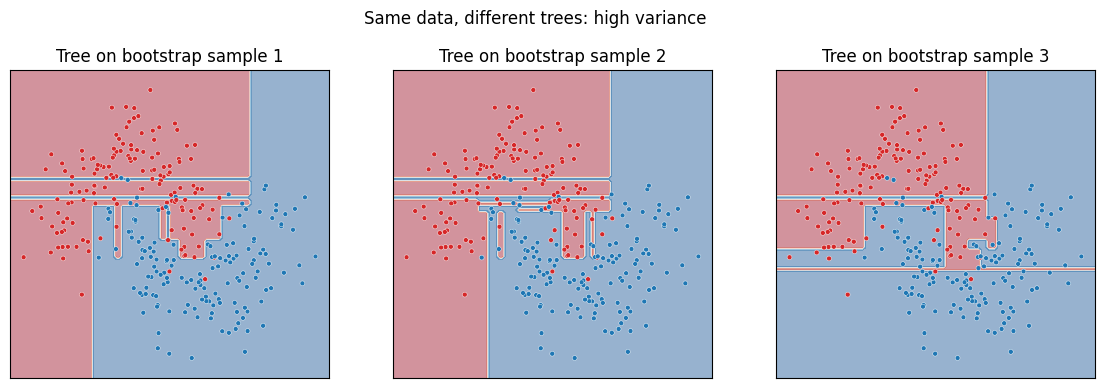

In [8]:
Xm, ym = make_moons(n_samples=300, noise=0.25, random_state=42)

def plot_boundary(model, ax, title, proba=False):
    # proba=True shades by predicted probability: hard boxes for one tree, smooth gradients for averaged ensembles
    DecisionBoundaryDisplay.from_estimator(model, Xm, ax=ax, cmap='RdBu', alpha=0.45, eps=0.2,
                                           response_method='predict_proba' if proba else 'predict')
    ax.scatter(Xm[:, 0], Xm[:, 1], c=np.where(ym == 1, 'tab:blue', 'tab:red'), s=12, edgecolor='white', linewidth=0.3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, ax in enumerate(axes):
    rows = np.random.default_rng(i).integers(0, len(Xm), len(Xm))
    t = DecisionTreeClassifier(random_state=0).fit(Xm[rows], ym[rows])
    plot_boundary(t, ax, f'Tree on bootstrap sample {i + 1}')
plt.suptitle('Same data, different trees: high variance', y=1.03);

# Part 2: Bagging and out-of-bag error
---
## Bootstrapping
A **bootstrap sample** is drawn **with replacement** and is the same size as the original data. Some rows appear more than once; others not at all.

In [9]:
rows = np.arange(10)
sample = np.random.default_rng(1).choice(rows, size=10, replace=True)
print('original rows:   ', rows)
print('bootstrap sample:', np.sort(sample))
print('left out ("out-of-bag"):', np.setdiff1d(rows, sample))

original rows:    [0 1 2 3 4 5 6 7 8 9]
bootstrap sample: [0 1 2 3 4 5 7 8 9 9]
left out ("out-of-bag"): [6]


In [10]:
# On average, about 37% of rows are left out of each bootstrap sample (1/e ≈ 0.368)
left_out = [1 - len(np.unique(np.random.default_rng(i).integers(0, 1000, 1000))) / 1000 for i in range(200)]
print(f'Average share left out: {np.mean(left_out):.3f}')

Average share left out: 0.369


## Bagging = **B**ootstrap **agg**regat**ing**
Train many deep trees, each on its own bootstrap sample, and let them vote. `oob_score=True` also gives a free estimate of test accuracy (see below).

In [11]:
bagging = evaluate('Bagging (100 trees)',
                   BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True,
                                     random_state=42, n_jobs=-1))

Bagging (100 trees): train 1.000 | test 0.941 | 12.2s


### How many trees do we need?
Each grey dot is one tree's test accuracy on its own. The line is the vote of the first *n* trees. Averaging lifts accuracy well above any single tree, then levels off. More trees never hurt accuracy; they just cost time.

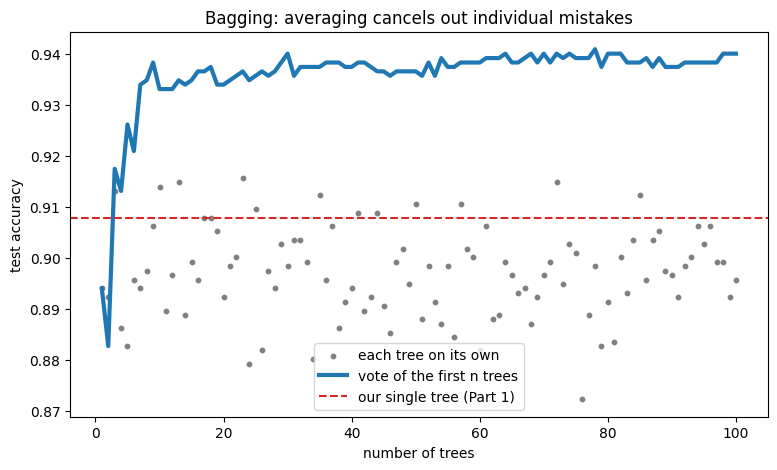

In [12]:
votes = np.array([est.predict(X_test.values) for est in bagging.estimators_])
running = [((votes[:n].mean(axis=0) >= 0.5) == y_test).mean() for n in range(1, len(votes) + 1)]
single = [(v == y_test).mean() for v in votes]

plt.scatter(range(1, len(single) + 1), single, s=10, color='grey', label='each tree on its own')
plt.plot(range(1, len(running) + 1), running, lw=3, label='vote of the first n trees')
plt.axhline(results['Single tree']['test accuracy'], color='tab:red', ls='--', label='our single tree (Part 1)')
plt.xlabel('number of trees'); plt.ylabel('test accuracy'); plt.title('Bagging: averaging cancels out individual mistakes')
plt.legend();

## Out-of-bag (OOB) error
Each tree never saw about 37% of the training rows. For every training email we can ask only the trees that **didn't** train on it: a free validation score, no extra split needed.

In [13]:
print(f'Bagging OOB accuracy:  {bagging.oob_score_:.3f}')
print(f'Bagging test accuracy: {results["Bagging (100 trees)"]["test accuracy"]:.3f}')

Bagging OOB accuracy:  0.942
Bagging test accuracy: 0.941


The OOB score lands close to the test score. That's why it's a useful check, especially when data is too scarce to set aside a validation set.

# Part 3: Random forests
---
**Problem with bagging:** if one feature is very strong (here, maybe `char_freq_$`), almost every tree splits on it first, so the trees look alike and make **similar mistakes**. Averaging similar trees helps less.

**Random forest fix:** at **every split**, each tree may only choose from a **random subset** of features (by default √57 ≈ 7 for classification). The trees become more different (**decorrelated**), so the vote cancels more mistakes.

In [14]:
forest = evaluate('Random forest (100 trees)',
                  RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1))
print(f'Random forest OOB accuracy: {forest.oob_score_:.3f}')

Random forest (100 trees): train 1.000 | test 0.951 | 0.4s
Random forest OOB accuracy: 0.953


### Seeing the decorrelation
How often do two trees from the same ensemble make the **same mistake**? Lower is better: diverse mistakes cancel out in the vote.

Bagging          0.295
Random forest    0.219
dtype: float64


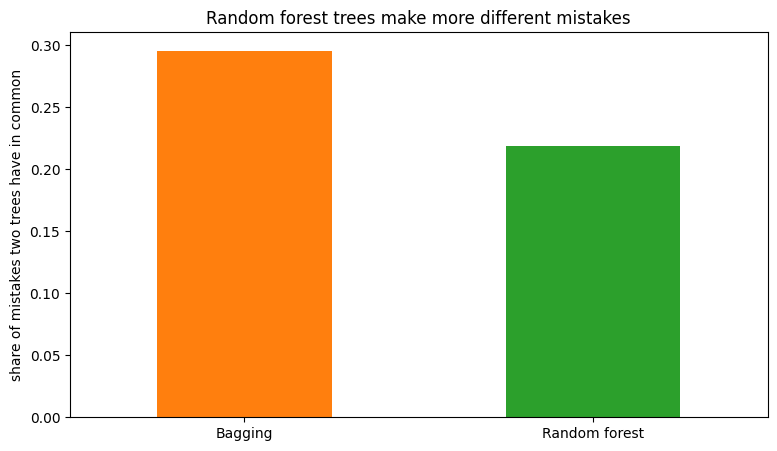

In [15]:
def shared_mistakes(ensemble):
    wrong = np.array([est.predict(X_test.values) != y_test.values for est in ensemble.estimators_[:50]])
    pairs = [(wrong[i] & wrong[j]).sum() / max(1, (wrong[i] | wrong[j]).sum())
             for i in range(len(wrong)) for j in range(i + 1, len(wrong))]
    return np.mean(pairs)

overlap = pd.Series({'Bagging': shared_mistakes(bagging), 'Random forest': shared_mistakes(forest)})
overlap.plot(kind='bar', color=['tab:orange', 'tab:green'], rot=0)
plt.ylabel('share of mistakes two trees have in common'); plt.title('Random forest trees make more different mistakes')
print(overlap.round(3))

### Which features matter?
We lose the single tree's flowchart, but we can still ask which features the forest relied on most (total Gini reduction, averaged over all trees).

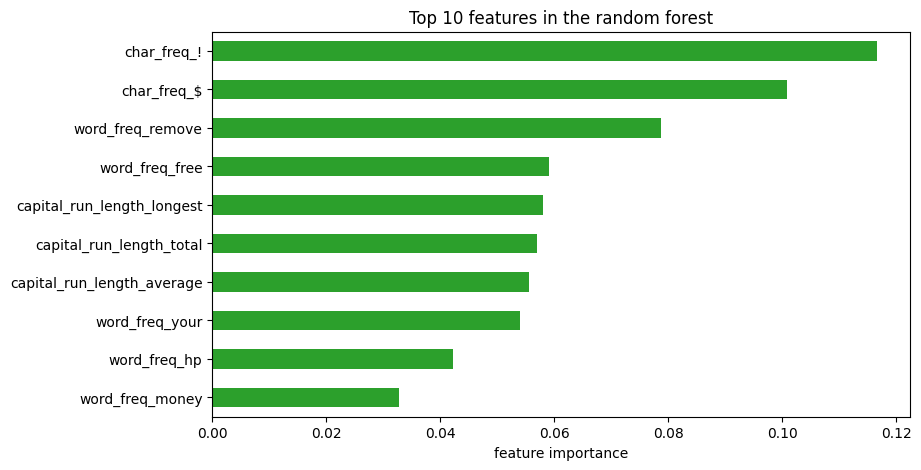

In [16]:
importance = pd.Series(forest.feature_importances_, index=X.columns).nlargest(10)[::-1]
importance.plot(kind='barh', color='tab:green')
plt.xlabel('feature importance'); plt.title('Top 10 features in the random forest');

Dollar signs, exclamation marks, "remove", "free" and CAPITALS: very spam-like! (Impurity-based importance can favour features with many distinct values; `sklearn.inspection.permutation_importance` is a more reliable check.)

---
## Back to slides
---

# Part 4: Boosting with AdaBoost
---
Bagging starts with **overfit** trees and averages them. Boosting does the **opposite**: it starts with very **underfit** trees (usually *stumps*: one question each) and adds them **one after another**, each focusing on the emails the previous ones got wrong.

How good is a single stump?

In [17]:
stump = evaluate('Single stump', DecisionTreeClassifier(max_depth=1))

Single stump: train 0.798 | test 0.780 | 0.0s


A stump is too simple (**high bias**): it asks one question. Now let AdaBoost combine 300 of them, re-weighting the misclassified emails after each round:

In [18]:
ada = evaluate('AdaBoost (300 stumps)', AdaBoostClassifier(n_estimators=300, random_state=42))

AdaBoost (300 stumps): train 0.950 | test 0.937 | 1.7s


### Watching boosting learn
`staged_score` gives the test accuracy after each round. The first stump is weak; each new one fixes some remaining mistakes. That's **bias** going down.

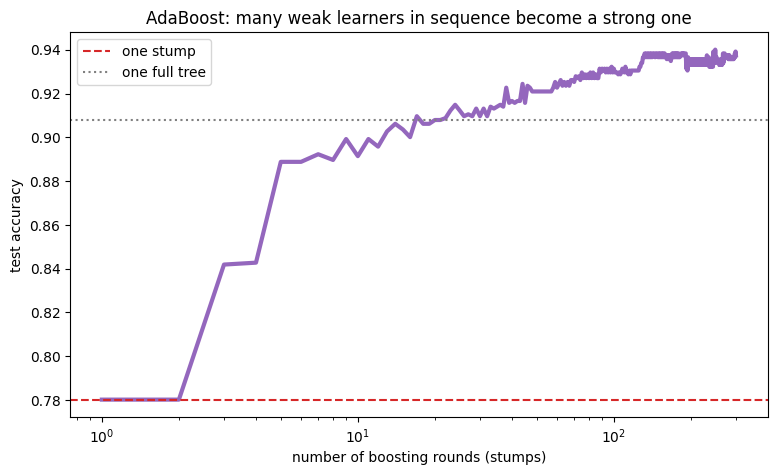

In [19]:
staged = list(ada.staged_score(X_test, y_test))
plt.plot(range(1, len(staged) + 1), staged, lw=3, color='tab:purple')
plt.axhline(results['Single stump']['test accuracy'], color='tab:red', ls='--', label='one stump')
plt.axhline(results['Single tree']['test accuracy'], color='grey', ls=':', label='one full tree')
plt.xlabel('number of boosting rounds (stumps)'); plt.ylabel('test accuracy'); plt.xscale('log')
plt.title('AdaBoost: many weak learners in sequence become a strong one'); plt.legend();

# Part 5: Gradient boosting
---
Gradient boosting fits each new tree to the **errors (residuals)** of the model so far: like golf, the first shot gets you near the hole and each putt corrects what's left. A simple regression example makes it visible:

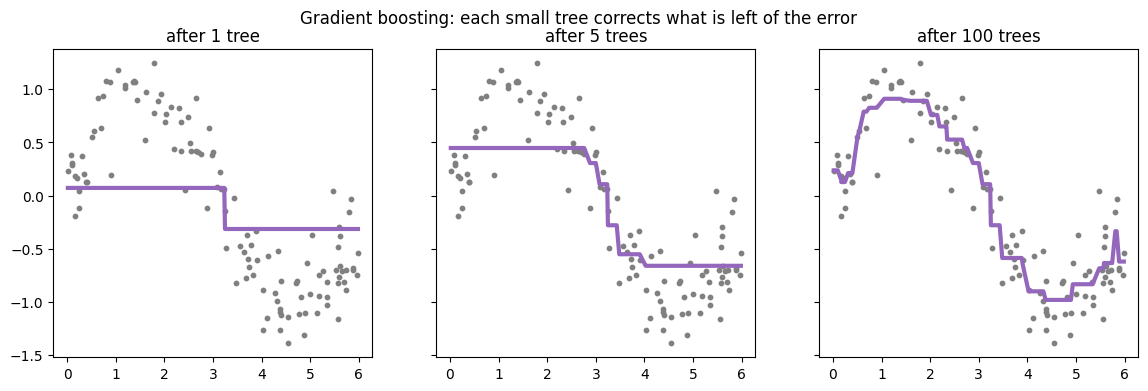

In [20]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 6, 120)).reshape(-1, 1)
target = np.sin(x).ravel() + rng.normal(0, 0.25, 120)

gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.3, max_depth=1, random_state=0).fit(x, target)
stages = list(gbr.staged_predict(x))
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, n in zip(axes, [1, 5, 100]):
    ax.scatter(x, target, s=10, color='grey')
    ax.plot(x, stages[n - 1], color='tab:purple', lw=3)
    ax.set_title(f'after {n} tree{"s" if n > 1 else ""}')
plt.suptitle('Gradient boosting: each small tree corrects what is left of the error');

### Learning rate vs number of trees
Each tree's correction is multiplied by the **learning rate**. A big learning rate learns fast but can overshoot; a small one learns slowly but steadily. They work as a pair: smaller learning rate → more trees needed.

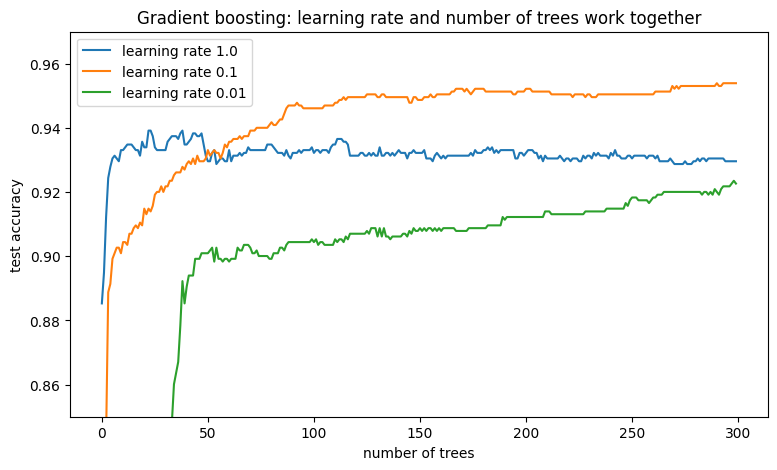

In [21]:
fig, ax = plt.subplots()
for lr in [1.0, 0.1, 0.01]:
    gb = GradientBoostingClassifier(n_estimators=300, learning_rate=lr, random_state=42).fit(X_train, y_train)
    ax.plot([(p == y_test).mean() for p in gb.staged_predict(X_test)], label=f'learning rate {lr}')
ax.set_xlabel('number of trees'); ax.set_ylabel('test accuracy'); ax.set_ylim(0.85, 0.97)
ax.set_title('Gradient boosting: learning rate and number of trees work together'); ax.legend();

In [22]:
gb = evaluate('Gradient boosting', GradientBoostingClassifier(random_state=42))   # defaults: 100 trees, lr 0.1, depth 3

Gradient boosting: train 0.968 | test 0.946 | 1.1s


### Fast, modern gradient boosting
`HistGradientBoostingClassifier` is scikit-learn's fast implementation (similar to **XGBoost** and **LightGBM**): it bins features to speed up training, handles missing values natively, and can stop early when it stops improving.

In [23]:
hgb = evaluate('HistGradientBoosting', HistGradientBoostingClassifier(random_state=42))

HistGradientBoosting: train 0.999 | test 0.957 | 0.7s


### Optional: XGBoost
XGBoost is a separate library (`pip install xgboost`) with a scikit-learn-style API. One gotcha with this data: XGBoost rejects column names containing `[`, `]` or `<`, and `char_freq_[` is one of ours, so we rename it.

In [24]:
try:
    from xgboost import XGBClassifier
    X_train_x = X_train.rename(columns=lambda c: c.replace('[', 'lbracket'))
    X_test_x = X_test.rename(columns=lambda c: c.replace('[', 'lbracket'))
    xgb = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, random_state=42, n_jobs=-1)
    start = time.time(); xgb.fit(X_train_x, y_train)
    results['XGBoost'] = {'train accuracy': xgb.score(X_train_x, y_train), 'test accuracy': xgb.score(X_test_x, y_test),
                          'fit seconds': time.time() - start}
    print(f"XGBoost: train {results['XGBoost']['train accuracy']:.3f} | test {results['XGBoost']['test accuracy']:.3f}")
except ImportError:
    print('XGBoost is not installed; run `pip install xgboost` to try it. Everything else works without it.')

XGBoost: train 0.988 | test 0.954


# Part 6: Bring it home
---
## Comparing everything on the same test emails

In [25]:
table = pd.DataFrame(results).T
table['test error'] = 1 - table['test accuracy']
table = table.sort_values('test accuracy')
table.round(3)

,train accuracy,test accuracy,fit seconds,test error
Single stump,0.798,0.780,0.001,0.220
Single tree,1.000,0.908,0.072,0.092
AdaBoost (300 stumps),0.950,0.937,1.720,0.063
Bagging (100 trees),1.000,0.941,12.248,0.059
Gradient boosting,0.968,0.946,1.128,0.054
Random forest (100 trees),1.000,0.951,0.366,0.049
XGBoost,0.988,0.954,5.020,0.046
HistGradientBoosting,0.999,0.957,0.654,0.043


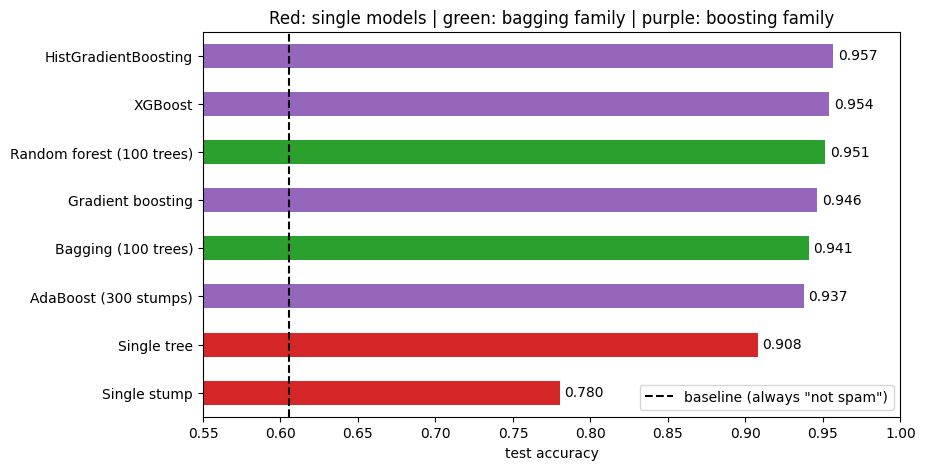

In [26]:
family = {'Single stump': 'tab:red', 'Single tree': 'tab:red', 'Bagging (100 trees)': 'tab:green',
          'Random forest (100 trees)': 'tab:green'}
colors = [family.get(n, 'tab:purple') for n in table.index]          # everything else is boosting
ax = table['test accuracy'].plot(kind='barh', color=colors, figsize=(9, 5))
base_line = ax.axvline(baseline, color='black', ls='--', label='baseline (always "not spam")')
for i, v in enumerate(table['test accuracy']):
    ax.text(v + 0.003, i, f'{v:.3f}', va='center')
ax.set_xlim(0.55, 1.0); ax.set_xlabel('test accuracy')
ax.set_title('Red: single models | green: bagging family | purple: boosting family'); ax.legend(handles=[base_line], loc='lower right');

In [27]:
tree_err = table.loc['Single tree', 'test error']
best = table['test error'].idxmin()
print(f'Single tree error: {tree_err:.1%} | best ensemble ({best}) error: {table.loc[best, "test error"]:.1%}')
print(f'The best ensemble makes {1 - table.loc[best, "test error"] / tree_err:.0%} fewer mistakes than one tree.')

Single tree error: 9.2% | best ensemble (HistGradientBoosting) error: 4.3%
The best ensemble makes 53% fewer mistakes than one tree.


## The same story in pictures
On the simulated moons, shaded by predicted probability (pale = unsure): one tree is always 100% sure and carves jagged boxes (high variance); bagging and random forests average many trees into smooth, more honest boundaries. One stump draws a single straight line (high bias); boosting builds it up into a good curved boundary.

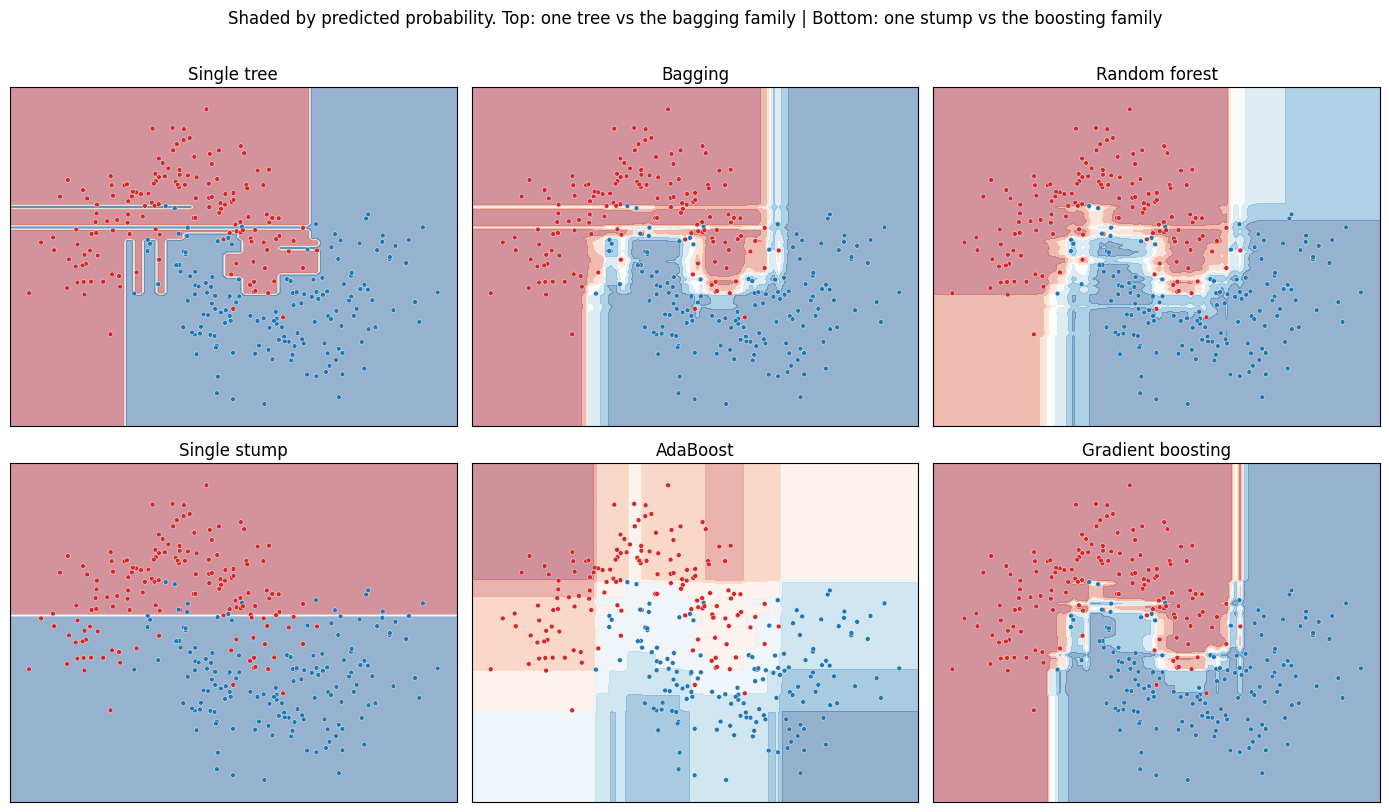

In [28]:
models = {'Single tree': DecisionTreeClassifier(random_state=0),
          'Bagging': BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0),
          'Random forest': RandomForestClassifier(n_estimators=100, random_state=0),
          'Single stump': DecisionTreeClassifier(max_depth=1),
          'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=0),
          'Gradient boosting': GradientBoostingClassifier(random_state=0)}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    plot_boundary(model.fit(Xm, ym), ax, name, proba=True)
plt.suptitle('Shaded by predicted probability. Top: one tree vs the bagging family | Bottom: one stump vs the boosting family', y=1.01)
plt.tight_layout();

## Which ensemble should I use?
| Situation | Try |
|---|---|
| A strong, reliable model with little tuning | **Random forest** (no scaling; free OOB estimate) |
| The last bit of accuracy on tabular data | **Gradient boosting** (`HistGradientBoosting`, XGBoost, LightGBM); tune `learning_rate` and the number of trees |
| Small or noisy data | **Random forest** (boosting can chase noise) |
| You must explain every decision | A **single tree** or **logistic regression** (or explain the ensemble with feature importance / SHAP) |
| Always | Compare with a **baseline** and a simple model |

## Key takeaways
- **One tree overfits and is unstable** (high variance).
- **Bagging** averages many trees trained on bootstrap samples: lower variance, plus a free **out-of-bag** score.
- **Random forests** add random features at each split, so the trees make different mistakes and the vote works better.
- **Boosting** adds weak learners in sequence, each fixing the last one's mistakes: lower bias. **Learning rate** and **number of trees** work together.
- On this data, ensembles make roughly **half as many mistakes** as a single tree.

## Your turn (extensions)
1. Change `max_features` in the random forest (try 2, 7, 20, 57). What happens at 57? *(It becomes bagging.)*
2. Give AdaBoost deeper trees: `AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), ...)`. Better or worse?
3. Use `GridSearchCV` to tune `learning_rate` and `max_iter` for `HistGradientBoostingClassifier`.